In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Chargement des données
_df = pd.read_csv("C:/Users/LE BON MEC/Documents/cours MM/TFC/data/dataset_DGI_ready.csv")

# Variables à exclure (demande utilisateur + fuite / redondance)
excluded_cols = [
    "assurance",
    "controle_technique",
    "vignette",
    "taxe_circulation_usd",
    "taxe_stationnement_usd",
    "age_vehicule",
    "charge_fiscale",
    "score",
    "score_final",
    "statut_fiscal",
]

X = _df.drop(columns=["statut_fiscal_encoded"] + excluded_cols)
y = _df["statut_fiscal_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = X.select_dtypes(include=["number"]).columns.tolist()

cat_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

num_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor_lr = ColumnTransformer([
    ("cat", cat_preprocessor, cat_cols),
    ("num", num_preprocessor, num_cols),
])

preprocessor_tree = ColumnTransformer([
    ("cat", cat_preprocessor, cat_cols),
    ("num", SimpleImputer(strategy="median"), num_cols),
])


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

model_lr = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("model", LogisticRegression(max_iter=2000, random_state=42)),
])

param_grid_lr = {
    "model__C": [0.1, 1.0, 10.0],
    "model__solver": ["lbfgs"],
    "model__penalty": ["l2"],
}

search_lr = GridSearchCV(
    estimator=model_lr,
    param_grid=param_grid_lr,
    scoring="f1_weighted",
    cv=5,
    n_jobs=1,
)

search_lr.fit(X_train, y_train)
model_lr = search_lr.best_estimator_

cv_lr = cross_val_score(model_lr, X_train, y_train, cv=5, scoring="f1_weighted")
print("Meilleurs paramètres LR:", search_lr.best_params_)
print("CV F1 weighted LR (moyenne):", cv_lr.mean())

y_pred_lr = model_lr.predict(X_test)


Meilleurs paramètres LR: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
CV F1 weighted LR (moyenne): 0.9026004607633491


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

model_rf = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestClassifier(random_state=42)),
])

param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
}

search_rf = GridSearchCV(
    estimator=model_rf,
    param_grid=param_grid_rf,
    scoring="f1_weighted",
    cv=5,
    n_jobs=1,
)

search_rf.fit(X_train, y_train)
model_rf = search_rf.best_estimator_

cv_rf = cross_val_score(model_rf, X_train, y_train, cv=5, scoring="f1_weighted")
print("Meilleurs paramètres RF:", search_rf.best_params_)
print("CV F1 weighted RF (moyenne):", cv_rf.mean())

y_pred_rf = model_rf.predict(X_test)


Meilleurs paramètres RF: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
CV F1 weighted RF (moyenne): 0.891172314176498


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

model_dt = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", DecisionTreeClassifier(random_state=42)),
])

param_grid_dt = {
    "model__max_depth": [3, 5, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2],
    "model__ccp_alpha": [0.0, 0.01],
}

search_dt = GridSearchCV(
    estimator=model_dt,
    param_grid=param_grid_dt,
    scoring="f1_weighted",
    cv=5,
    n_jobs=1,
)

search_dt.fit(X_train, y_train)
model_dt = search_dt.best_estimator_

cv_dt = cross_val_score(model_dt, X_train, y_train, cv=5, scoring="f1_weighted")
print("Meilleurs paramètres DT:", search_dt.best_params_)
print("CV F1 weighted DT (moyenne):", cv_dt.mean())

y_pred_dt = model_dt.predict(X_test)


Meilleurs paramètres DT: {'model__ccp_alpha': 0.01, 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
CV F1 weighted DT (moyenne): 0.9099038169238505


In [7]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
import matplotlib.pyplot as plt
import seaborn as sns


def evaluate_model(y_true, y_pred, model_name):
    print(f"\n===== {model_name} =====")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Balanced Accuracy:", balanced_accuracy_score(y_true, y_pred))
    print("Precision (macro):", precision_score(y_true, y_pred, average="macro", zero_division=0))
    print("Recall (macro):", recall_score(y_true, y_pred, average="macro", zero_division=0))
    print("F1 (macro):", f1_score(y_true, y_pred, average="macro", zero_division=0))
    print("Precision (weighted):", precision_score(y_true, y_pred, average="weighted", zero_division=0))
    print("Recall (weighted):", recall_score(y_true, y_pred, average="weighted", zero_division=0))
    print("F1 (weighted):", f1_score(y_true, y_pred, average="weighted", zero_division=0))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Matrice de confusion - {model_name}")
    plt.xlabel("Prédiction")
    plt.ylabel("Réel")
    plt.show()



=== Résumé des performances sur l’échantillon test ===
                Modèle  Accuracy  Balanced Accuracy  Precision (macro)  \
0        Decision Tree  0.918019           0.908886           0.925413   
1  Logistic Regression  0.893669           0.892671           0.891049   
2        Random Forest  0.878247           0.869989           0.872212   

   Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  \
0        0.908886    0.915973              0.918988           0.918019   
1        0.892671    0.891844              0.893560           0.893669   
2        0.869989    0.867481              0.877453           0.878247   

   F1 (weighted)  ROC-AUC (macro)  
0       0.917275         0.977921  
1       0.893601         0.978464  
2       0.874623         0.963820  


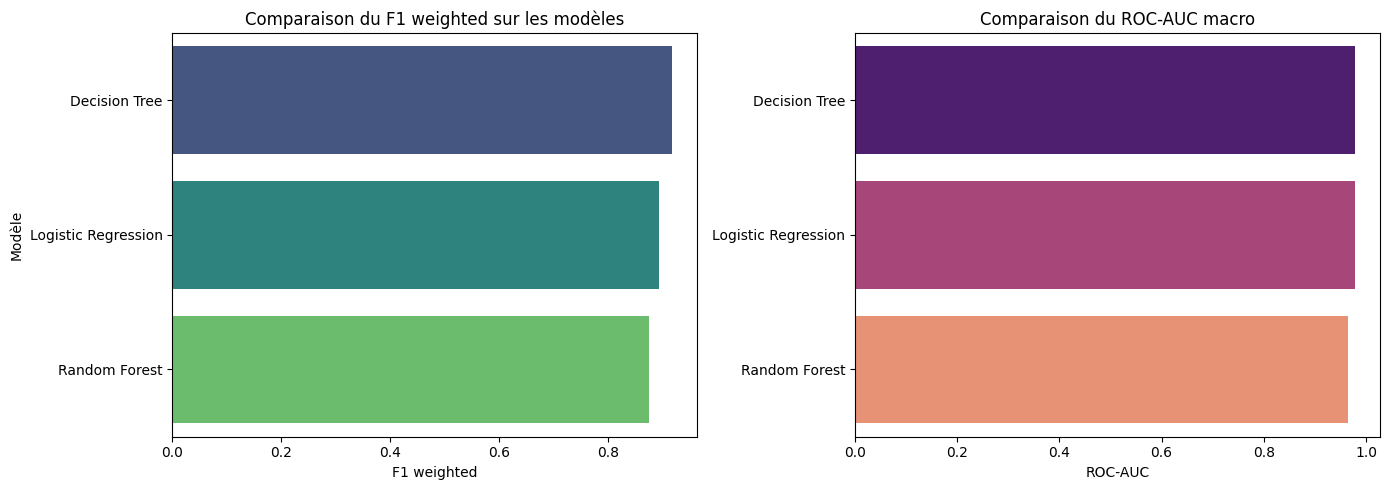


=== Validation croisée (5 folds, scoring=F1 weighted) ===
                Modèle  CV F1 weighted
0        Decision Tree        0.909904
1  Logistic Regression        0.902600
2        Random Forest        0.891172


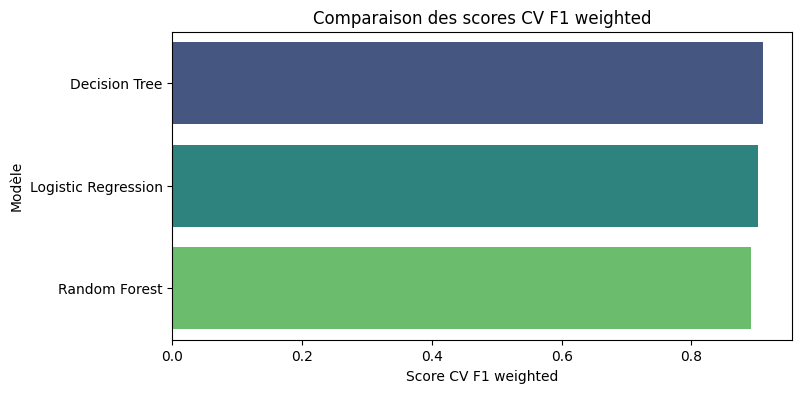

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


# Fonction de calcul des métriques de test + ROC-AUC

def compute_metrics(model, model_name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    classes = np.unique(y_train)

    if y_proba.shape[1] == 2:
        roc_auc = roc_auc_score(y_test, y_proba[:, 1])
    else:
        y_test_bin = pd.get_dummies(y_test).reindex(columns=classes, fill_value=0).to_numpy()
        roc_auc = roc_auc_score(y_test_bin, y_proba, multi_class="ovr")

    return {
        "Modèle": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (macro)": roc_auc,
    }


metrics_df = pd.DataFrame([
    compute_metrics(model_lr, "Logistic Regression"),
    compute_metrics(model_rf, "Random Forest"),
    compute_metrics(model_dt, "Decision Tree"),
]).sort_values("F1 (weighted)", ascending=False).reset_index(drop=True)

print("\n=== Résumé des performances sur l’échantillon test ===")
print(metrics_df)

# Graphique 1 : comparaison des performances test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=metrics_df, x="F1 (weighted)", y="Modèle", hue="Modèle", palette="viridis", dodge=False, legend=False, ax=axes[0])
axes[0].set_title("Comparaison du F1 weighted sur les modèles")
axes[0].set_xlabel("F1 weighted")
axes[0].set_ylabel("Modèle")

sns.barplot(data=metrics_df, x="ROC-AUC (macro)", y="Modèle", hue="Modèle", palette="magma", dodge=False, legend=False, ax=axes[1])
axes[1].set_title("Comparaison du ROC-AUC macro")
axes[1].set_xlabel("ROC-AUC")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Graphique 2 : validation croisée (CV)
cv_df = pd.DataFrame([
    {"Modèle": "Logistic Regression", "CV F1 weighted": cv_lr.mean()},
    {"Modèle": "Random Forest", "CV F1 weighted": cv_rf.mean()},
    {"Modèle": "Decision Tree", "CV F1 weighted": cv_dt.mean()},
]).sort_values("CV F1 weighted", ascending=False).reset_index(drop=True)

print("\n=== Validation croisée (5 folds, scoring=F1 weighted) ===")
print(cv_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=cv_df, x="CV F1 weighted", y="Modèle", hue="Modèle", palette="viridis", dodge=False, legend=False)
plt.title("Comparaison des scores CV F1 weighted")
plt.xlabel("Score CV F1 weighted")
plt.ylabel("Modèle")
plt.show()




=== Analyse des erreurs de classification ===
                Modèle  Erreurs  Taux d'erreur
1        Random Forest      150       0.121753
0  Logistic Regression      131       0.106331
2        Decision Tree      101       0.081981


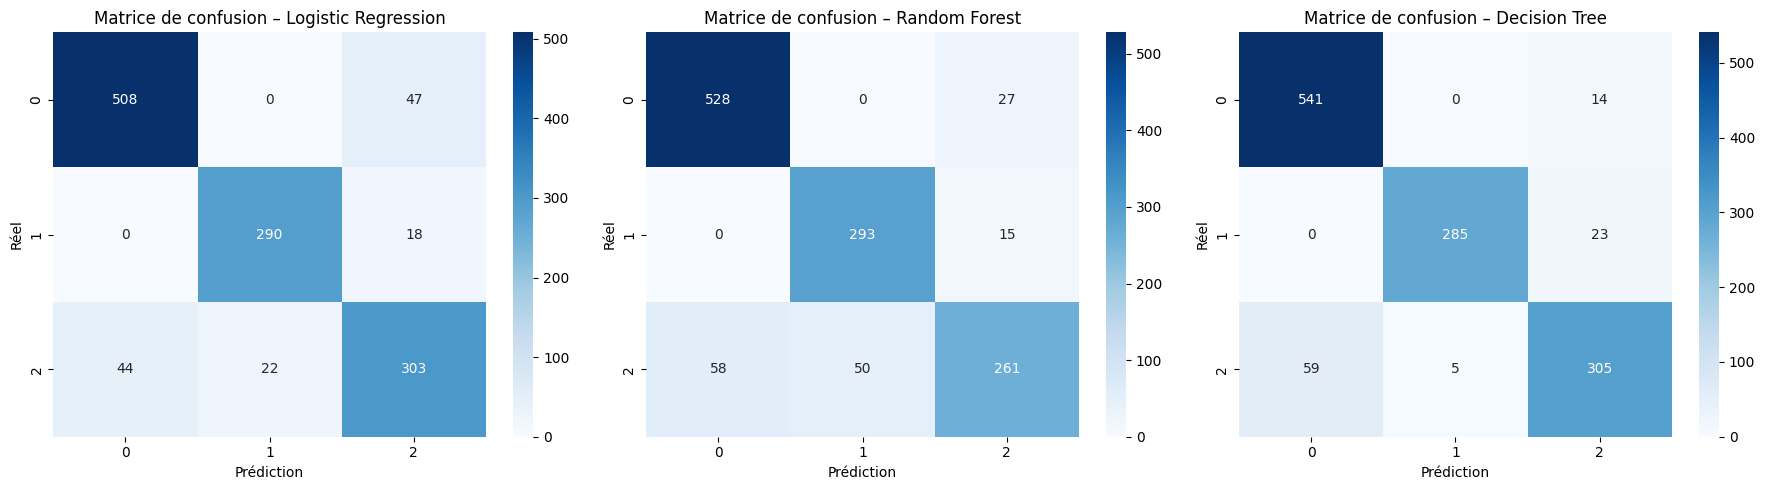

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Analyse des erreurs de classification
models = {
    "Logistic Regression": model_lr,
    "Random Forest": model_rf,
    "Decision Tree": model_dt,
}

error_summary = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    n_errors = int((y_test != y_pred).sum())
    error_rate = n_errors / len(y_test)
    error_summary.append({"Modèle": name, "Erreurs": n_errors, "Taux d'erreur": error_rate})

error_df = pd.DataFrame(error_summary).sort_values("Erreurs", ascending=False)
print("\n=== Analyse des erreurs de classification ===")
print(error_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"Matrice de confusion – {name}")
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réel")

plt.tight_layout()
plt.show()


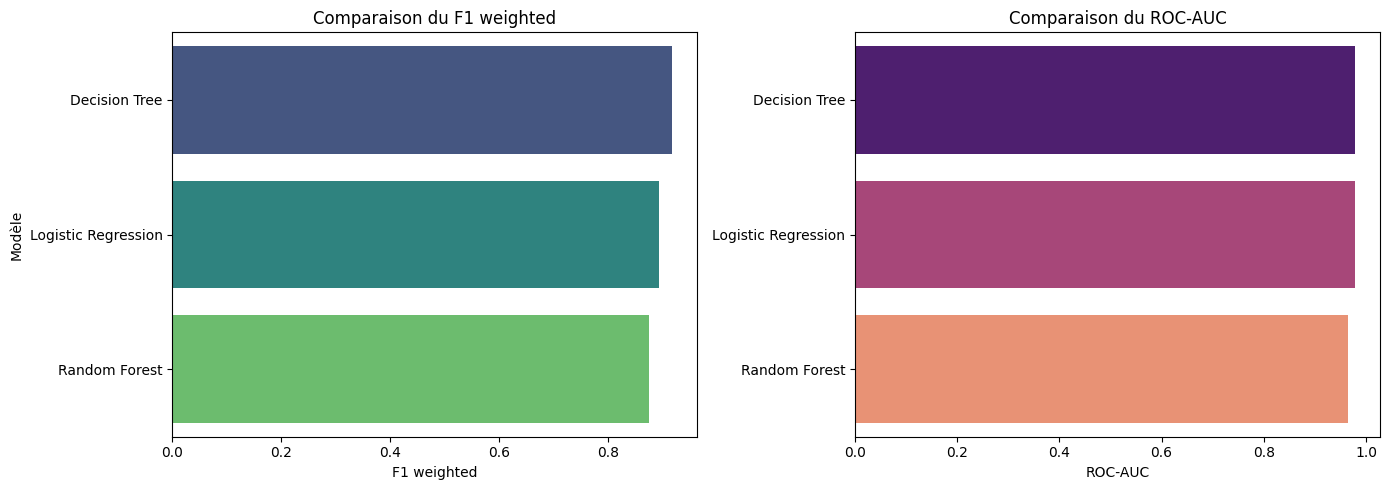

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Graphique complémentaire de comparaison des performances
comparison_df = pd.DataFrame([
    {"Modèle": "Logistic Regression", "F1 weighted": metrics_df.loc[metrics_df['Modèle'] == 'Logistic Regression', 'F1 (weighted)'].iloc[0], "ROC-AUC": metrics_df.loc[metrics_df['Modèle'] == 'Logistic Regression', 'ROC-AUC (macro)'].iloc[0]},
    {"Modèle": "Random Forest", "F1 weighted": metrics_df.loc[metrics_df['Modèle'] == 'Random Forest', 'F1 (weighted)'].iloc[0], "ROC-AUC": metrics_df.loc[metrics_df['Modèle'] == 'Random Forest', 'ROC-AUC (macro)'].iloc[0]},
    {"Modèle": "Decision Tree", "F1 weighted": metrics_df.loc[metrics_df['Modèle'] == 'Decision Tree', 'F1 (weighted)'].iloc[0], "ROC-AUC": metrics_df.loc[metrics_df['Modèle'] == 'Decision Tree', 'ROC-AUC (macro)'].iloc[0]},
]).sort_values("F1 weighted", ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=comparison_df, x="F1 weighted", y="Modèle", hue="Modèle", palette="viridis", dodge=False, legend=False, ax=axes[0])
axes[0].set_title("Comparaison du F1 weighted")
axes[0].set_xlabel("F1 weighted")
axes[0].set_ylabel("Modèle")

sns.barplot(data=comparison_df, x="ROC-AUC", y="Modèle", hue="Modèle", palette="magma", dodge=False, legend=False, ax=axes[1])
axes[1].set_title("Comparaison du ROC-AUC")
axes[1].set_xlabel("ROC-AUC")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


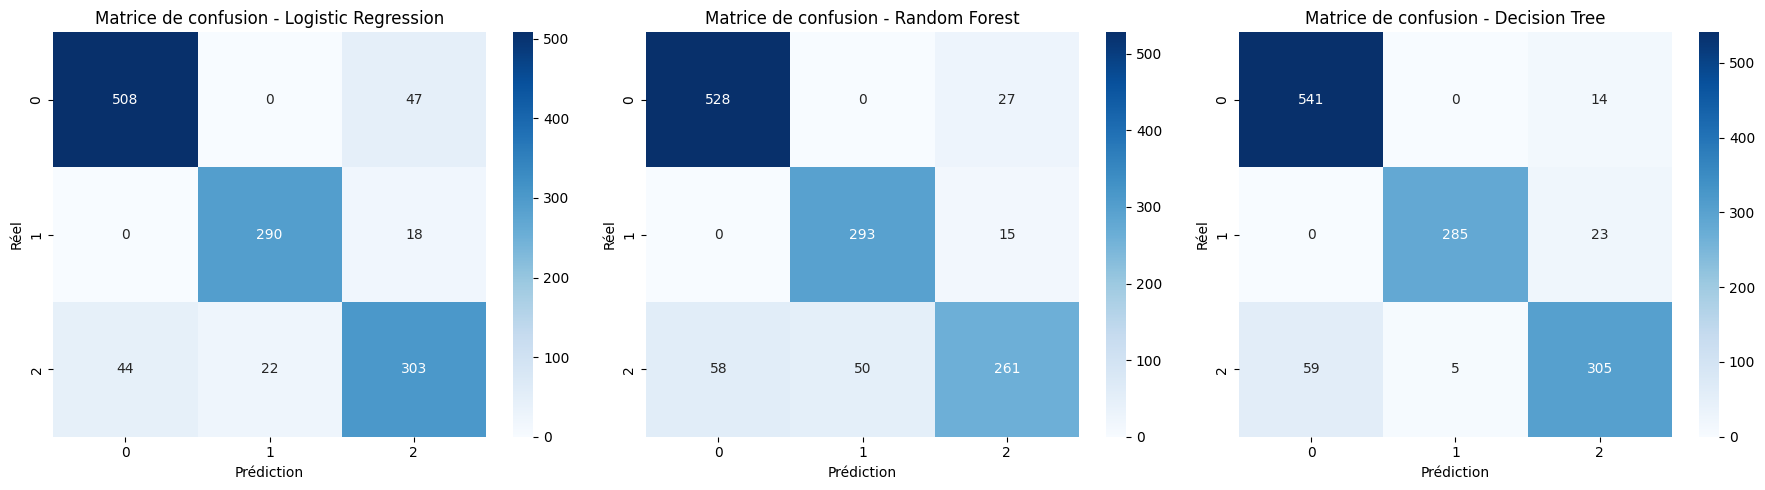

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Matrices de confusion des 3 modèles (alignées horizontalement)
models = {
    "Logistic Regression": model_lr,
    "Random Forest": model_rf,
    "Decision Tree": model_dt,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"Matrice de confusion - {name}")
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réel")

plt.tight_layout()
plt.show()


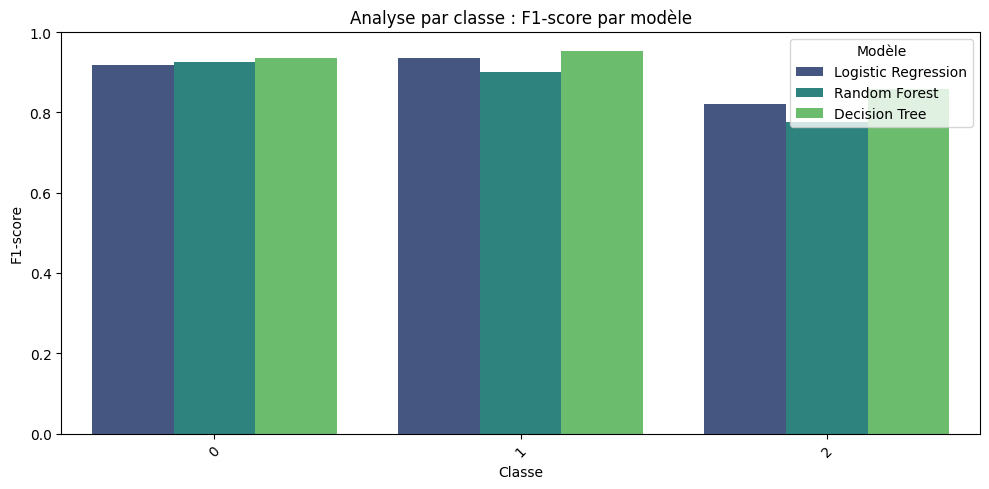


=== Résumé F1-score par classe ===
             Modèle Classe  Precision   Recall  F1-score
      Decision Tree      0   0.901667 0.974775  0.936797
      Decision Tree      1   0.982759 0.925325  0.953177
      Decision Tree      2   0.891813 0.826558  0.857947
Logistic Regression      0   0.920290 0.915315  0.917796
Logistic Regression      1   0.929487 0.941558  0.935484
Logistic Regression      2   0.823370 0.821138  0.822252
      Random Forest      0   0.901024 0.951351  0.925504
      Random Forest      1   0.854227 0.951299  0.900154
      Random Forest      2   0.861386 0.707317  0.776786


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# Analyse par classe (vue synthétique et visuelle)
models = {
    "Logistic Regression": model_lr,
    "Random Forest": model_rf,
    "Decision Tree": model_dt,
}

reports = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    reports[name] = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

rows = []
for model_name, report in reports.items():
    for cls, metrics in report.items():
        if isinstance(metrics, dict) and 'f1-score' in metrics and cls not in ('accuracy', 'macro avg', 'weighted avg'):
            rows.append({
                'Modèle': model_name,
                'Classe': cls,
                'Precision': metrics.get('precision', 0),
                'Recall': metrics.get('recall', 0),
                'F1-score': metrics.get('f1-score', 0),
            })

report_df = pd.DataFrame(rows)

plt.figure(figsize=(10, 5))
sns.barplot(data=report_df, x='Classe', y='F1-score', hue='Modèle', palette='viridis')
plt.title('Analyse par classe : F1-score par modèle')
plt.xlabel('Classe')
plt.ylabel('F1-score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print('\n=== Résumé F1-score par classe ===')
print(report_df.sort_values(['Modèle', 'Classe']).to_string(index=False))


=== Validation croisée du meilleur modèle (Decision Tree, 5 plis) ===
  Pli  F1 weighted
Pli 1     0.921820
Pli 2     0.903823
Pli 3     0.908941
Pli 4     0.909255
Pli 5     0.905680

Moyenne globale : 0.9099038169238505


C:\Users\LE BON MEC\AppData\Local\Temp\ipykernel_124\2100663060.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cv_best_df, x='Pli', y='F1 weighted', palette='viridis')


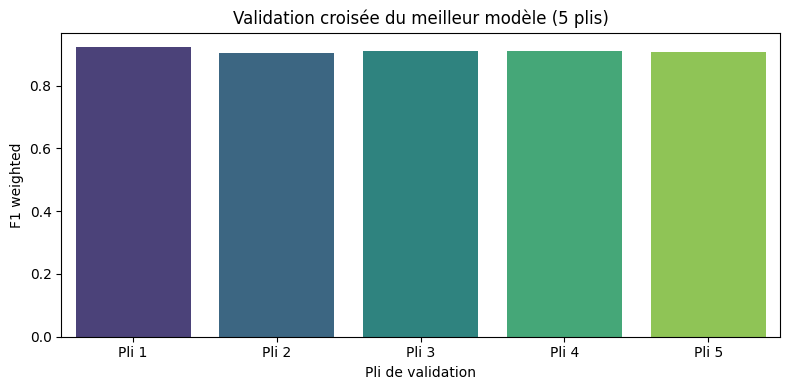

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score

# Validation croisée du meilleur modèle (Decision Tree) sur 5 plis
best_model = model_dt
cv_best = cross_val_score(best_model, X_train, y_train, cv=5, scoring='f1_weighted')

cv_best_df = pd.DataFrame({
    'Pli': [f'Pli {i+1}' for i in range(5)],
    'F1 weighted': cv_best
})

print('=== Validation croisée du meilleur modèle (Decision Tree, 5 plis) ===')
print(cv_best_df.to_string(index=False))
print('\nMoyenne globale :', cv_best.mean())

plt.figure(figsize=(8, 4))
sns.barplot(data=cv_best_df, x='Pli', y='F1 weighted', palette='viridis')
plt.title('Validation croisée du meilleur modèle (5 plis)')
plt.xlabel('Pli de validation')
plt.ylabel('F1 weighted')
plt.tight_layout()
plt.show()
